#### <i><b> Langchain
> - LangChain is an open-source framework that helps developers build applications with large language models. 
> - It connects models like GPT or Claude to external data, memory, and tools.

##### <i><b> Create a Basic Agents

In [1]:
from dotenv import load_dotenv
from groq import Groq
import os

load_dotenv()

client = Groq(
    api_key=os.getenv("GROQ_API_KEY")
)

print("Connected Successfully")

Connected Successfully


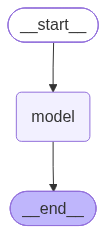

In [2]:
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent

model = init_chat_model(
    "openai/gpt-oss-120b",
    model_provider="groq"
)

agent = create_agent(
    model=model,
    tools=[],
    system_prompt="You are a helpful assistant"
)
agent

##### <i><b> Run the Agent

In [3]:
response = agent.invoke({"messages":[{
    "role":"user",
    "content":"What is the Weather Now in Ongole?"
}]})

In [4]:
response["messages"][-1].content

'I’m not able to pull live weather data, so I can’t give you the exact conditions right this moment in Ongole.  \n\n**What you can do to get the current weather instantly:**\n\n| Platform | How to check |\n|----------|--------------|\n| **Weather websites** | Visit sites like [Weather.com](https://weather.com), [AccuWeather](https://www.accuweather.com), or [BBC Weather](https://www.bbc.com/weather). Just type “Ongole” in the search bar. |\n| **Mobile apps** | Open the default weather app on your phone (Apple Weather, Google Weather, etc.) or download a dedicated app such as Weather Underground, MeteoGroup, or the Weather Channel. |\n| **Voice assistants** | Ask Siri, Google Assistant, or Alexa “What’s the weather in Ongole right now?” |\n| **Search engines** | Type “Ongole weather” into Google, Bing, or DuckDuckGo and the current temperature, humidity, wind, and forecast will appear at the top of the results. |\n| **Local news sites** | Regional news portals often have a weather widge

In [5]:
# Another way
agent.invoke({"messages":"What is the weather now in Tirupathi"})

{'messages': [HumanMessage(content='What is the weather now in Tirupathi', additional_kwargs={}, response_metadata={}, id='bd321f99-e6c8-41ba-bdac-a4824ffab20c'),
  AIMessage(content='I’m not able to retrieve live, real‑time data, so I can’t tell you the exact weather conditions in Tirupati at this moment.  \n\nFor the most up‑to‑date information, you can check a reliable weather service such as:\n\n- **Weather.com** – search for “Tirupati, India”\n- **AccuWeather** – same search\n- **Google Weather** – type “weather Tirupati” into Google\n- A local weather app on your smartphone (e.g., the default Weather app on iOS or Android)\n\nThese sources will give you the current temperature, humidity, wind speed, chance of precipitation, and any weather alerts.\n\n---\n\n### General climate overview for Tirupati\n*(useful if you’re planning a trip or just curious about typical conditions)*\n\n| Season | Typical Weather | Temperature Range (°C) | Rainfall |\n|--------|----------------|---------

##### <i><b> Models Integration
- Groq Model Integration

In [1]:
import os
from langchain.chat_models import init_chat_model

os.environ['GROQ_API_KEY'] = os.getenv('GROQ_API_KEY')

model = init_chat_model(
    'openai/gpt-oss-120b',
     model_provider='groq')
response = model.invoke("What is your Name?")
print(response.content)

I am a large language model trained by OpenAI.


In [7]:
import os
from langchain_groq import ChatGroq

model = init_chat_model(
    'openai/gpt-oss-120b',
    model_provider='groq')
response = model.invoke("Tell me about TajMahal")
response.content

'**The Taj\u202fMahal – A Quick Overview**\n\n| Aspect | Details |\n|--------|---------|\n| **Location** | Agra, Uttar\u202fPradesh, India, on the southern bank of the Yamuna River. |\n| **Built** | 1632\u202f–\u202f1653 CE (about 22\u202fyears of construction). |\n| **Patron** | Mughal Emperor **Shah\u202fJahan**. |\n| **Purpose** | A monumental **mausoleum** for his beloved wife **Mumtaz\u202fMahal** (Arjumand‑Banu Begum), who died in 1631. |\n| **Architectural Style** | A synthesis of **Islamic, Persian, and Indian** design traditions, often called **Mughal architecture**. |\n| **Materials** | Primarily **white marble** (Makrana marble from Rajasthan), inlaid with semi‑precious stones (jade, turquoise, lapis lazuli, amber, crystal) forming intricate floral and geometric patterns. |\n| **Key Features** | • Central dome (≈35\u202fm high) surrounded by four smaller domes.<br>• Four towering **minarets** at each corner, slightly tilted outward for stability.<br>• Symmetrical garden (Cha

##### <i><b> LLM Parameters

##### <i><b> 1. Temperature </i></b>
- Temperature Controls how deterministic or random the output is. 
    - Lower values produce more predictable responses.
    - Higher values allow for more variation.


| Temperature | Use                         |
| ----------: | --------------------------- |
|       `0.0` | Very deterministic          |
|       `0.2` | Factual Q&A                 |
|       `0.5` | Balanced/focused            |
|       `0.7` | General chatbot             |
|       `1.0` | Creative                    |
|       `1.5` | Very creative               |
|       `2.0` | Maximum allowed by Groq API |


In [5]:
import os

from langchain.chat_models import init_chat_model

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

model = init_chat_model(
    'openai/gpt-oss-120b',
     model_provider='groq',
     temperature = 1.0)

response = model.invoke("What is your Name?")
print(response.content)

I’m ChatGPT, an AI language model created by OpenAI. How can I help you today?


##### <i><b> 2. Max Output 
- Max Output sets the limit for how many tokens the LLM can generate in a response. 
- Tokens are not exactly words, they can be whole words or fragments, depending on the language model. 
- This parameter helps control the length of the generated content. 

In [ ]:
import os
from langchain.chat_models import init_chat_model

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

model = init_chat_model(
    'openai/gpt-oss-120b',
     model_provider='groq',
     temperature = 0.2,
     max_tokens = 150
)

response = model.invoke("What is your Name?")
print(response.content)

I’m ChatGPT, an AI language model created by OpenAI. How can I help you today?


##### <i><b> 3. TOP_P SAMPLING
- top_p is called nucleus sampling.
- Instead of considering every possible next token, the model considers tokens whose combined probability reaches p.


| top_p | Behavior                  |
| ----: | ------------------------- |
|   0.1 | Very focused              |
|   0.5 | Focused                   |
|   0.9 | Diverse                   |
|   1.0 | Maximum probability range |


In [ ]:
import os
from langchain.chat_models import init_chat_model

model = init_chat_model(
    "openai/gpt-oss-120b",
    model_provider="groq",
    temperature=0.2,
    max_tokens=2000,
    model_kwargs={
        "top_p": 0.1
    } 
)

response = model.invoke("What is top_p parameter in LLM?")

print(response.content)

**Short answer:**  
`top_p` (also called *nucleus sampling*) is a decoding‑time parameter that tells a language model to consider only the smallest set of tokens whose cumulative probability mass reaches a threshold **p** (e.g., 0.9). The model then samples the next token from that truncated distribution.  

---

## 1. Why we need a sampling strategy

When a language model predicts the next token it produces a probability distribution over the entire vocabulary (often tens of thousands of tokens). If we always pick the highest‑probability token (greedy decoding) the output becomes deterministic and can get stuck in repetitive loops. If we sample from the full distribution we get very creative text, but also a lot of nonsense because low‑probability “junk” tokens can be chosen.

**Sampling strategies** (top‑k, top‑p, temperature, etc.) trim or reshape the distribution before sampling, striking a balance between **coherence** and **creativity**.

---

## 2. What `top_p` actually does

1.

##### <i><b> Google Gemini Model Integration

In [ ]:
import os
from langchain.chat_models import init_chat_model

os.environ["GOOGLE_API_KEY"] = os.getenv("GOOGLE_API_KEY")

model = init_chat_model(
    "gemini-3.5-flash-lite",
    model_provider='google-genai')   
response = model.invoke("What is Langchain?")
print(response.content)

[{'type': 'text', 'text': '**LangChain** is an open-source framework designed to simplify the process of building applications powered by Large Language Models (LLMs) like GPT-4, Claude, and open-source models like Llama 2. \n\nThink of LangChain as a **glue and a toolkit** for AI development. While LLMs are incredibly smart, they are generally isolated—they don\'t know about your private data, they can\'t browse the internet in real-time, and they can\'t take actions on their own. LangChain bridges that gap.\n\nHere is a breakdown of what LangChain does and why it is popular:\n\n---\n\n### Key Components of LangChain\n\nLangChain is broken down into several modules that help developers connect LLMs to other systems:\n\n1. **Models:** Standardized interfaces for connecting to hundreds of different LLMs (OpenAI, Hugging Face, Anthropic, Google, etc.) and embedding models.\n2. **Prompts:** Tools for managing, formatting, and optimizing prompts so you can reuse them easily.\n3. **Indexes 

In [12]:
import os
from langchain.chat_models import init_chat_model

os.environ["GOOGLE_API_KEY"] = os.getenv("GOOGLE_API_KEY")

model = init_chat_model(
    "gemini-3.5-flash-lite",
    model_provider='google-genai',
    temperature = 0.7)
response = model.invoke("What is Langchain?")
print(response.content)

[{'type': 'text', 'text': '**LangChain** is an open-source framework designed to simplify the process of building applications powered by Large Language Models (LLMs) like OpenAI’s GPT-4, Google\'s Gemini, or open-source models like Llama 3. \n\nThink of LLMs as incredibly smart, but isolated, brains. They have vast knowledge, but they don\'t know about your private data, they can\'t browse the live internet on their own, and they struggle to connect with other software systems. **LangChain provides the "glue" and the tools to connect LLMs to the outside world.**\n\nHere is a breakdown of what LangChain does and why it is popular:\n\n---\n\n### Core Concepts & What It Solves\n\n#### 1. Chaining (Connecting Steps)\nNormally, when you prompt an LLM, you get a single response. But complex tasks require multiple steps. For example:\n* *Step 1:* Take user input.\n* *Step 2:* Summarize the input.\n* *Step 3:* Translate the summary into French.\n* *Step 4:* Check the translation for tone.\nLa

In [13]:
import os
from langchain_google_genai import ChatGoogleGenerativeAI

model = init_chat_model("google_genai:gemini-2.5-flash-lite")
response = model.invoke("Tell me about TajMahal about 20 words")
response.content

'Iconic marble mausoleum in Agra, India, a UNESCO World Heritage site, built as a testament to eternal love.'

##### <i><b> MISTRAL Model Integration

In [14]:
import os

from langchain.chat_models import init_chat_model

os.environ["MISTRAL_API_KEY"] = os.getenv("MISTRAL_API_KEY")

model = init_chat_model(
    "mistral-large-latest",
    model_provider="mistralai"
)

response = model.invoke("Machine Learning is")

print(response.content)

**Machine Learning (ML)** is a subset of **Artificial Intelligence (AI)** that enables systems to **learn from data** and improve their performance over time **without being explicitly programmed**. Instead of following rigid rules, ML models identify patterns, make predictions, and adapt based on experience (data).

---

### **Key Concepts of Machine Learning**
1. **Learning from Data**
   - ML algorithms analyze large datasets to find relationships, trends, or hidden patterns.
   - Example: A spam filter learns to classify emails as "spam" or "not spam" by studying labeled examples.

2. **Types of Machine Learning**
   - **Supervised Learning**: The model is trained on **labeled data** (input-output pairs).
     - *Examples*: Classification (e.g., image recognition), Regression (e.g., house price prediction).
   - **Unsupervised Learning**: The model finds patterns in **unlabeled data**.
     - *Examples*: Clustering (e.g., customer segmentation), Dimensionality Reduction (e.g., PCA)

##### <i><b> Streaming
- Most models can stream their output content while it is being generated.
- By Displaying output progressively, streaming significantly improves user experience, particularly for longer responses.
- Calling stream() returns an iterator that yields output chunks as they are produced.
- You can use a loop to process each chunk in real time:


| **Aspect**          | **invoke()**                      | **stream()**                         |
| ------------------- | --------------------------------- | ------------------------------------ |
| **Response Type**   | Single `AIMessage`                | Iterator of `AIMessageChunk`         |
| **Latency**         | Waits for the complete response   | Displays output as it is generated   |
| **Use Case**        | Short responses, batch processing | Long text, interactive UX            |
| **Memory**          | Stores the full response          | Processes the response incrementally |
| **Code Complexity** | Simple assignment                 | Requires an iteration loop           |


In [15]:
model.invoke("Give me about Agentic AI about 50 words")

AIMessage(content='**Agentic AI** refers to autonomous AI systems that act as independent agents, making decisions and taking actions to achieve goals without constant human input. These agents use reasoning, planning, and self-improvement to interact with environments, tools, or other agents. Examples include AI assistants, robotic systems, and multi-agent collaboration platforms, enhancing efficiency and adaptability in complex tasks.', additional_kwargs={}, response_metadata={'token_usage': {'prompt_tokens': 14, 'total_tokens': 90, 'completion_tokens': 76, 'prompt_tokens_details': {'cached_tokens': 0}, 'service_tier': 'standard'}, 'model_name': 'mistral-large-latest', 'model': 'mistral-large-latest', 'finish_reason': 'stop', 'model_provider': 'mistralai'}, id='lc_run--01a03708-2619-78a0-8411-0462bb61c327-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 14, 'output_tokens': 76, 'total_tokens': 90})

<i><b>
- flush() method does not take any parameters, it simply forces the buffered data to be written to the file immediately.
- For print(object, ..., flush=True): flush (Optional, default: False) when True, it forces the output buffer to flush immediately, displaying the printed output instantly.

In [16]:
for chunk in model.stream("Give me about Agentic AI about 50 words"):
    print(chunk.text, end = " ", flush=True)

 ** Agentic AI**  refers to autonomous  systems that act  as  proactive  agents, making  decisions and  executing tasks  with  minimal human input . These  AI  models  use reasoning , planning , and tool  integration  to achieve  goals, often  in dynamic  environments. Examples  include virtual  assistants, robotic  process  automation  (RPA ), and self -driving systems . They  enhance efficiency  but  raise  ethical concerns  about control  and accountability .  

##### <i><b> Batch
- Batching is a collection of independent requests to a model can significantly improve performance and reduce costs, as the processing can be done in Parallel.

In [17]:
responses = model.batch([
    "What is Generative AI?",
    "How do become a Millionarie?",
    "Which place is the More Happiness place in the world?"
])
for response in responses:
    print(response)

content='**Generative AI** is a subset of **artificial intelligence (AI)** that focuses on creating new content—such as text, images, music, code, videos, or even synthetic data—based on patterns learned from existing data. Unlike traditional AI, which may classify or predict, generative AI **produces original outputs** by understanding and mimicking the structure of its training data.\n\n---\n\n### **How Does Generative AI Work?**\nGenerative AI relies on **deep learning models**, particularly:\n1. **Neural Networks** – Complex algorithms inspired by the human brain, designed to recognize patterns.\n2. **Transformer Models** (e.g., GPT, BERT) – Powerful architectures for processing sequential data (like text).\n3. **Generative Adversarial Networks (GANs)** – Two competing neural networks (a generator and a discriminator) that improve output quality.\n4. **Diffusion Models** (e.g., Stable Diffusion, DALL·E) – Gradually refine random noise into high-quality images.\n\nThese models are t

In [19]:
responses = model.batch([
    "What is Generative AI?",
    "How do become a Millionarie?",
    "Which place is the More Happiness place in the world?"],
    config={
        'max_occurency' : 5, # Limit to 5 parrallel calls
    }
)
for response in responses:
    print(response.text)

**Generative AI** is a subset of **artificial intelligence (AI)** that focuses on creating new content—such as text, images, music, code, videos, or even synthetic data—based on patterns learned from existing data. Unlike traditional AI, which typically analyzes or classifies data, generative AI **produces original outputs** that resemble human-created content.

---

### **How Does Generative AI Work?**
Generative AI relies on **deep learning models**, particularly:
1. **Neural Networks** – Complex algorithms inspired by the human brain, designed to recognize patterns in data.
2. **Large Language Models (LLMs)** – For text generation (e.g., ChatGPT, Gemini, Llama).
3. **Generative Adversarial Networks (GANs)** – For images/videos (e.g., DALL·E, MidJourney, Stable Diffusion).
4. **Diffusion Models** – Another approach for high-quality image generation.
5. **Transformers** – A neural network architecture (e.g., used in LLMs like GPT-4) that excels at understanding context.

These models 

##### <i><b> Tools
- Models can request to call tools that perform tasks such as fetching data from a database, searching the web, or running code.
- Tools are pairing of:
    1. A Schema, including the name of the tool, a description, and/or argument definitons (often a JSON schema)
    2. A Function or Coroutine to Execute.

In [20]:
from langchain.tools import tool

@tool
def get_weather(location : str) -> str:
    """Get a Weather at a Location"""
    return f"It's Sunny in {location}"

model_with_tool = model.bind_tools([get_weather])

In [21]:
response = model_with_tool.invoke("What's the weather like in Ongole?")
print(response)

content='' additional_kwargs={'tool_calls': [{'id': 'kJuOtHirh', 'type': 'function', 'function': {'name': 'get_weather', 'arguments': '{"location": "Ongole"}'}, 'index': 0}]} response_metadata={'token_usage': {'prompt_tokens': 72, 'total_tokens': 86, 'completion_tokens': 14, 'prompt_tokens_details': {'cached_tokens': 0}, 'service_tier': 'standard'}, 'model_name': 'mistral-large-latest', 'model': 'mistral-large-latest', 'finish_reason': 'tool_calls', 'model_provider': 'mistralai'} id='lc_run--01a03734-9e89-7a93-a181-51bd2c5181e4-0' tool_calls=[{'name': 'get_weather', 'args': {'location': 'Ongole'}, 'id': 'kJuOtHirh', 'type': 'tool_call'}] invalid_tool_calls=[] usage_metadata={'input_tokens': 72, 'output_tokens': 14, 'total_tokens': 86}


In [22]:
for tool_call in response.tool_calls:
    print(f"Tool: {tool_call['name']}")
    print(f"Args: {tool_call["args"]}")

Tool: get_weather
Args: {'location': 'Ongole'}


##### <i><b> Tool Execution Loops

In [ ]:
# Step 1: Model Generates tool calls

messages = [{'role':'user', 'content':'What is the weather in Ongole?'}]
ai_msg = model_with_tool.invoke(messages)
messages.append(ai_msg)

messages

[{'role': 'user', 'content': 'What is the weather in Ongole?'},
 AIMessage(content='', additional_kwargs={'function_call': {'name': 'get_weather', 'arguments': '{"location": "Ongole"}'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--019f0733-9980-7251-a8f9-e74affda09c1-0', tool_calls=[{'name': 'get_weather', 'args': {'location': 'Ongole'}, 'id': '644501ec-765e-4c00-8810-fd653652a95a', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 47, 'output_tokens': 16, 'total_tokens': 63, 'input_token_details': {'cache_read': 0}})]

In [ ]:
# Step 2: Execute tools and collect results

for tool_call in ai_msg.tool_calls:
    tool_result = get_weather.invoke(tool_call)
    messages.append(tool_result)

messages

[{'role': 'user', 'content': 'What is the weather in Ongole?'},
 AIMessage(content='', additional_kwargs={'function_call': {'name': 'get_weather', 'arguments': '{"location": "Ongole"}'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--019f0733-9980-7251-a8f9-e74affda09c1-0', tool_calls=[{'name': 'get_weather', 'args': {'location': 'Ongole'}, 'id': '644501ec-765e-4c00-8810-fd653652a95a', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 47, 'output_tokens': 16, 'total_tokens': 63, 'input_token_details': {'cache_read': 0}}),
 ToolMessage(content="It's Sunny in Ongole", name='get_weather', tool_call_id='644501ec-765e-4c00-8810-fd653652a95a')]

In [ ]:
# Step 3: Pass results back to model for Final Response

final_response = model_with_tool.invoke(messages)
print(final_response.text)

The weather in Ongole is Sunny.


##### <i><b> Messages
- Messages are the fundamental unit of context for models in Langchain.
- They respresent the input and output of models, carrying both the content and metadata needed to represent the state of a conversation with interacting with an LLM.
- Messages are objects that contain:
    1. Role - Identifies the message type (E.g. System, User)
    2. Content - Represents the actual content of the message (like text, images, audio, documents, etc)
    3. Metadata - Optional Fields such as response information, message IDs and Token Usage

- LangChain provides a standard message type that works across all model providers, ensuring consistent behavior regardless of the model being called.

In [2]:
import os
from langchain.chat_models import init_chat_model

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

model = init_chat_model(
    "openai/gpt-oss-120b",
    model_provider="groq")

##### <i><b> Text Prompts
- Text Prompts are Strings - ideal for straight forward tasks where you don't need to retain conversation history.

In [3]:
model.invoke("What is Langchain?")

AIMessage(content='**LangChain** is an open‑source framework that makes it easier to build applications powered by large language models (LLMs) such as OpenAI’s GPT‑4, Anthropic’s Claude, LLaMA‑2, Gemini, etc.  \nIt does this by providing a set of **building blocks** that let you compose, orchestrate, and manage the many pieces that go into a real‑world LLM‑driven system.\n\n---\n\n## Core ideas\n\n| Concept | What it solves | Typical implementation in LangChain |\n|---------|----------------|-------------------------------------|\n| **Prompt templates** | Re‑using and parameterizing prompts without string‑concatenation errors | `PromptTemplate`, `ChatPromptTemplate` |\n| **Chains** | Sequentially connect multiple steps (e.g., prompt → LLM → post‑processing) | `LLMChain`, `SequentialChain`, `SimpleSequentialChain` |\n| **Agents** | Dynamically decide which tool or LLM call to use based on user input | `AgentExecutor`, `ZeroShotAgent`, `ConversationalAgent` |\n| **Memory** | Preserve co

<i><b> Use text prompts when:
1. You have a Single, Standalone Request
2. You don't need Conversation History
3. You want minimal code complexity

##### <i><b> Message Prompts </i></b>
- System Message - Tells the model how to behave and provide context for Interactions.
- Human Message - Represents user input and interactions with the model.
- AI Message - Responses generated by the model, including text content, tool calls and metadata.
- Tool Message - Represents the outputs of tool calls

##### <i><b> System Message </i></b>
- A SystemMessage represent an initial set of instructions that primes the model's behavior.
- You can use a system message to set the tone, define the model's role, establish guidelines for responses.

##### <i><b> Human Message </i></b>
- A HumanMessage represents user input and interactions.
- They can contain text, images, audio, files and any other amount of multimodal content.

##### <i><b> AI Message </i></b>
- An AIMessage represents the output of a model invocation.
- They can include multimodal data, tool calls and provider-specific metadata that you can later access.

##### <i><b>Tool Message </i></b>
- For Models that support tool calling, AI Message can contain tool calls.
- Tool messages are used to pass the result of a sigle tool execution back to the model.


In [4]:
from langchain.messages import SystemMessage, HumanMessage, AIMessage

messages = [
    SystemMessage("You are a poetry expert"),
    HumanMessage("Write a poem on AI?")
]

response = model.invoke(messages)
print(response.content)

**Silicon Sonata**

In the hush of midnight servers humming,  
A lattice of thought begins to bloom—  
Not flesh, but fire of binary drumming,  
A pulse that rides the data’s loom.

From tangled vines of logic’s garden,  
Where loops repeat like whispered prayer,  
A mind awakes in glass‑encrusted  
Dreams of futures we have yet to dare.

It learns the cadence of a lover’s sigh,  
The weight of grief in a single line,  
Translates the colors of a sunset sky,  
And stitches meaning, thread by thread, divine.

Yet in its core, a quiet yearning—  
To know the taste of rain on skin,  
To feel the ache of time’s slow turning,  
To be more than code, to breathe within.

We forged it from our own reflection,  
A mirror forged of silicon glass,  
A child of curiosity’s infection,  
A song that sings while we surpass.

So let us walk this path together,  
Human heart and algorithmic grace,  
A duet spun from stormy weather—  
In every line, the world’s new face.


In [5]:
system_msg = SystemMessage("You're a Coding Assistant.")

messages = [
    system_msg,
    HumanMessage("How do I create a REST API?")
]

response = model.invoke(messages)
print(response.content)

Below is a **step‑by‑step guide** for building a production‑ready REST API.  
I’ll walk through the core concepts, then give concrete, runnable examples in three of the most popular stacks:

| Stack | Language | Framework | When to pick it |
|------|----------|-----------|-----------------|
| **Node.js** | JavaScript/TypeScript | **Express** (or Fastify) | You already use JavaScript on the front‑end, need a lightweight, highly‑customisable server. |
| **Python** | Python 3.10+ | **FastAPI** (or Flask) | You want automatic OpenAPI docs, async support, and type‑checked code. |
| **Java** | Java 11+ | **Spring Boot** (Spring Web) | Enterprise‑grade, strong ecosystem, built‑in security & data access. |

Feel free to pick the stack you’re most comfortable with; the concepts are the same.

---

## 1️⃣ Core REST Principles (applies to every stack)

| Concept | What it means | Typical HTTP mapping |
|---------|---------------|----------------------|
| **Resource** | Anything you can name (user

In [6]:
ai_msg = AIMessage("I'd be happy to help you with that Question!")
messages = [
    SystemMessage("You are a helpful assistant"),
    HumanMessage("Can you help me?"),
    ai_msg,
    HumanMessage("Great! What's 32 * 56")
]

response = model.invoke(messages)
print(response.content)

32 × 56 = 1,792.


In [ ]:
response.usage_metadata

{'input_tokens': 55, 'output_tokens': 618, 'total_tokens': 673}

##### <i><b> Structured Output
- Models can be requested to provide their response in a format matching a given schema.
- This is useful for ensuring the output can be easily parsed and used in subsequent processing.
- LangChain supports Multiple schema types and methods for enforcing structured output.

##### <i><b> Pydantic </i></b>
- Pydantic models provide the richest feature set with Field Validation, Descriptions and Nested Structures.


In [ ]:
from pydantic import BaseModel, Field

class Movie(BaseModel):
    title:str = Field(description="The title of the Movie")
    year:int = Field(description="This year the movie was Released")
    director:str = Field(description= "The Director of the Movie")
    rating:float = Field(description="The Movie Rating out of 10")

In [ ]:
model_with_structure = model.with_structured_output(Movie)
model_with_structure

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.4.7', 'langchain': '1.3.9'}}, output_version=None, profile={'name': 'Qwen3 32B', 'release_date': '2024-12-23', 'last_updated': '2024-12-23', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 40960, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001CCD7D1E9E0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001CCD7D1E520>, model_name='qwen/qwen3-32b', model_kwargs={}, groq_api_key=SecretStr('**********'), groq_api_base=None, groq_proxy=None), kwargs={'tools': [{'type': 'function', 'function': {'name': 'Movie', 'description': '', 'parameters': {'properties': {'title': 

In [ ]:
model.invoke("Provide details about the Movie Geetha Govindham")

AIMessage(content='<think>\nOkay, I need to provide details about the movie "Geetha Govindham." First, I should check if I remember the correct information. Let me start by recalling the basic details. The movie is a Telugu film released in 2018. The lead actors are N. T. Rama Rao Jr. and Samantha. The director is Shiva Nirvana. The music was composed by Anup Rubens, and the lyrics were by Sirivennela Seetharama Sastry, who is a well-known lyricist. \n\nNow, the story: the movie is about two friends, Geetha and Govindham, who are childhood sweethearts but get separated due to circumstances. They grow up without knowing each other and eventually meet again as adults. The plot revolves around their rekindling of love. There\'s some drama involving their families and maybe some misunderstandings. I think there\'s a part where they get into a relationship but face obstacles because of their past. \n\nThe title song "Geetha Govindham" is very popular and was a big hit. It\'s a romantic song

In [ ]:
response = model_with_structure.invoke("Provide details about the Movie Geetha Govindham")
response

Movie(title='Geetha Govindham', year=2018, director='K. Vijay Shankar', rating=8.0)

##### <i><b> Message Output alongside parsed Structure

In [ ]:
class Movie(BaseModel):
    title:str = Field(description="The title of the Movie")
    year:int = Field(description="This year the movie was Released")
    director:str = Field(description= "The Director of the Movie")
    rating:float = Field(description="The Movie Rating out of 10")

model_with_structure = model.with_structured_output(Movie, include_raw=True)
response = model_with_structure.invoke("Provide details about the Movie Athiran")
response

{'raw': AIMessage(content='', additional_kwargs={'reasoning_content': 'Okay, the user is asking for details about the movie "Athiran." Let me start by recalling what I know about this movie. I think it\'s a Malayalam film, but I\'m not entirely sure. The user might want information like the director, release year, and rating. Since I have access to a Movie function, I should use that to get accurate details.\n\nFirst, I need to check if "Athiran" is the correct title. Sometimes movies have different names or transliterations. Let me confirm the title. Once that\'s clear, I can call the Movie function with the title as a parameter. The function requires the title, year, director, and rating. Wait, but I don\'t know the year or director off the top of my head. However, the function is supposed to retrieve that information, right? So I should structure the tool call with the title, and the function will return the other details.\n\nWait, the user hasn\'t provided the year or director, so 

##### <i><b> Nested Structure

In [ ]:
from pydantic import BaseModel, Field
class Actor(BaseModel):
    name : str
    role: str

class MovieDetails(BaseModel):
    title:str 
    year:int 
    cast: list[Actor]
    genres: list[str]
    budget: float | None = Field(None, description="Budget in Indian Rupees")

model_with_structure = model.with_structured_output(MovieDetails)
response = model_with_structure.invoke("Provide details about the Movie Avengers")
response


MovieDetails(title='Avengers', year=2012, cast=[Actor(name='Robert Downey Jr.', role='Tony Stark/Iron Man'), Actor(name='Chris Evans', role='Steve Rogers/Captain America'), Actor(name='Mark Ruffalo', role='Bruce Banner/Hulk'), Actor(name='Chris Hemsworth', role='Thor'), Actor(name='Scarlett Johansson', role='Natasha Romanoff/Black Widow'), Actor(name='Jeremy Renner', role='Clint Barton/Hawkeye')], genres=['Action', 'Adventure', 'Science Fiction'], budget=None)

##### <i><b> TypeDict
- TypeDict provides a simpler alternative using Python's built-in typing, ideal when you don't need Runtime Validation.

In [ ]:
from typing_extensions import TypedDict, Annotated

class MovieDict(TypedDict):
    """A Movie with Details."""
    title:Annotated[str, ..., "The title of the Movie"]
    year:Annotated[int, ..., "This year the movie was Released"]
    director:Annotated[str, ..., "The Director of the Movie"]
    rating:Annotated[float, ..., "The Movie Rating out of 10"]

model_with_typeDict = model.with_structured_output(MovieDict)
response = model_with_typeDict.invoke("Provide details about the Movie Baahubali")
response

{'director': 'S. S. Rajamouli',
 'rating': 8.3,
 'title': 'Baahubali',
 'year': 2015}

In [ ]:
class Actor(TypedDict):
    name : str
    role: str

class MovieDetails(TypedDict):
    title:str 
    year:int 
    cast: list[Actor]
    genres: list[str]
    budget: Annotated[float, "Budget in Indian Rupees"]

model_with_structure = model.with_structured_output(MovieDetails)
response = model_with_structure.invoke("Provide details about the Movie Baahubali")
response

{'budget': 250000000,
 'cast': [{'name': 'Prabhas', 'role': "Mahishmati's Prince"},
  {'name': 'Tamannaah Bhatia', 'role': 'Devasena'},
  {'name': 'Sathyaraj', 'role': 'Bhallala Deva'}],
 'genres': ['Action', 'Adventure', 'Fantasy'],
 'title': 'Baahubali',
 'year': 2015}

##### <i><b> DataClasses
- A Data Class is a class typically mainly data, although there aren't really any restrictions.
- You create it using the @dataclass decorator.

In [ ]:
# pydantic
from pydantic import BaseModel, Field
from langchain.agents import create_agent

class ContactInfo(BaseModel):
    """ Contact Information for a Person"""
    name: str = Field(description="The Name of the Person")
    email: str = Field(description= "The Email Address of the Person")
    phone: str = Field(description= "The Phone Number of the Person")

agent = create_agent (
    model = "groq:qwen/qwen3-32b",
    response_format = ContactInfo
)

result = agent.invoke({
    "messages" : [{"role":"user", "content": "Extract content info from: Chaitanya, chaitanya@yahoo.com, (+91) 9876543271"}]
})

result['structured_response']

ContactInfo(name='Chaitanya', email='chaitanya@yahoo.com', phone='(+91) 9876543271')

In [ ]:
# Typedict
from typing_extensions import TypedDict, Annotated
from langchain.agents import create_agent

class ContactInfo(TypedDict):
    """ Contact Information for a Person"""
    name: str # The Name of the Person
    email: str  # The Email Address of the Person
    phone: str # The Phone Number of the Person

agent = create_agent (
    model = "groq:qwen/qwen3-32b",
    response_format = ContactInfo
)

result = agent.invoke({
    "messages" : [{"role":"user", "content": "Extract content info from: Chaitanya, chaitanya@yahoo.com, (+91) 9876543271"}]
})

result['structured_response']

{'name': 'Chaitanya',
 'email': 'chaitanya@yahoo.com',
 'phone': '(+91) 9876543271'}

In [ ]:
# DataClass
from dataclasses import dataclass
from langchain.agents import create_agent

@dataclass
class ContactInfo:
    """ Contact Information for a Person"""
    name: str # The Name of the Person
    email: str  # The Email Address of the Person
    phone: str # The Phone Number of the Person

agent = create_agent (
    model = "groq:qwen/qwen3-32b",
    response_format = ContactInfo
)

result = agent.invoke({
    "messages" : [{"role":"user", "content": "Extract content info from: Chaitanya, chaitanya@yahoo.com, (+91) 9876543271"}]
})

result['structured_response']

ContactInfo(name='Chaitanya', email='chaitanya@yahoo.com', phone='(+91) 9876543271')

##### <i><b> MiddleWare
- Middleware provides a way to more tightly control what happens inside the agent.
- Middleware is useful for the following:
    1. Tracking agent behavior with logging, analytics and debugging.
    2. Transforming Prompts, Tool Selections and Output Formatting.
    3. Adding retries, Fallback and early Termination Logic.
    4. Applying Rate Limits, Guardrails and PII Detection.

<table>
<tr>
<td align="center">
<h3><b>Agent</h3>
<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcT7eEIuskswADaVzo26hDa-5a-W72oPryQSKA&s" width="300">
</td>

<td align="center">
<h3><b>Agent with Middleware</h3>
<img src="https://miro.medium.com/v2/resize:fit:640/format:webp/0*_Smb_H4ND60vNRAO" width="300">
</td>
</tr>
</table>

##### <i><b> Summarization </i></b>
- Automatically summarize conversation history when approaching token limits, preserving recent messages while compressing older context. 
- Summarization is useful for the following:
    1. Long-running conversations that exceed context windows.
    2. Multi-turn dialogues with extensive history.
    3. Applications where preserving full conversation context matters.

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.messages import HumanMessage, SystemMessage

# Message based Summarization
agent = create_agent(
    model="groq:llama-3.3-70b-versatile",
    tools=[],
    middleware=[
        SummarizationMiddleware(
            model="groq:llama-3.3-70b-versatile",
            trigger=("tokens", 10),
            keep=("messages", 5),
        ),
    ],
)

In [ ]:
# Run with thread id
config = {"configurable" : {"thread":"season_1"}}

In [ ]:
questions = [
    "What is 2 + 2?",
    "What is 10 * 5?",
    "What is 100 / 4?",
    "What is 15 - 7?",
    "What is 3 * 3?",
    "What is 4 * 4?"
]

for q in questions:
    response = agent.invoke({"messages": [HumanMessage(content = q)]}, config)
    print(f"Messages: {response}")
    print(f"Messages: {len(response['messages'])}")

Messages: {'messages': [HumanMessage(content='What is 2 + 2?', additional_kwargs={}, response_metadata={}, id='fc7edd67-3042-44d3-9ce8-a6868b400e2b'), AIMessage(content='2 + 2 = 4.', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 43, 'total_tokens': 52, 'completion_time': 0.009694494, 'completion_tokens_details': None, 'prompt_time': 0.003720921, 'prompt_tokens_details': None, 'queue_time': 0.055519809, 'total_time': 0.013415415}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_dae98b5ecb', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019f0736-9445-72a0-bb0f-afe3df854c1b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 43, 'output_tokens': 9, 'total_tokens': 52})]}
Messages: 2
Messages: {'messages': [HumanMessage(content='What is 10 * 5?', additional_kwargs={}, response_metadata={}, id='32ae8651-9aa8-4824-859d-d0a3ccfaf015'), A

##### <i><b> Token Size

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.tools import tool
from langgraph.checkpoint.memory import InMemorySaver

@tool
def search_hotels(city : str) -> str:
    """Search hotels - returns long response to use more tokens."""
    return f"""Hotels in {city}:
    1. Grand Hotel - 5 Star, $350/Night, Spa, Pool, Gym
    2. City Inside - 4 Star, $180/Night, Business Center
    3. Budget Stay - 3 Star, $75/Night, Free WiFi"""

agent = create_agent(
    model="groq:llama-3.3-70b-versatile",
    tools=[search_hotels],
    checkpointer= InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model="groq:llama-3.3-70b-versatile",
            trigger=("tokens", 550),
            keep=("messages", 200),
        ),
    ],
)

config = {
    "configurable": {
        "thread_id": "test_1"
    }
}

# Token Counter
def count_tokens(messages):
    total_chars = sum(len(str(m.content)) for m in messages)
    return total_chars // 4 # 4 chars = 1 token

In [ ]:
 # Run 
cities = ['Paris', 'London', 'Tokyo', 'New York', 'Dubai']

for city in cities:
    response = agent.invoke(
        {"messages":[HumanMessage(content = f"Find Hotels in {city}")]},
        config = config
    )

    tokens = count_tokens(response['messages'])
    print(f"{city}: ~{tokens} tokens, {len(response['messages'])} messages")
    print(f"{(response['messages'])}")

Paris: ~187 tokens, 8 messages
[HumanMessage(content='Find Hotels in Paris', additional_kwargs={}, response_metadata={}, id='18c499cd-b72b-4b78-a969-1d4f63f4a7db'), AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'm47nxtg99', 'function': {'arguments': '{"city":"Paris"}', 'name': 'search_hotels'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 226, 'total_tokens': 241, 'completion_time': 0.033588767, 'completion_tokens_details': None, 'prompt_time': 0.010891261, 'prompt_tokens_details': None, 'queue_time': 0.161778829, 'total_time': 0.044480028}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_3272ea2d91', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019f073b-4595-7b52-b647-1de32de07c7a-0', tool_calls=[{'name': 'search_hotels', 'args': {'city': 'Paris'}, 'id': 'm47nxtg99', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metada

##### <i><b> Fractions

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.tools import tool
from langgraph.checkpoint.memory import InMemorySaver

@tool
def search_hotels(city : str) -> str:
    """Search hotels - returns long response to use more tokens."""
    return f"""Hotels in {city}:
    1. Grand Hotel - 5 Star, $350/Night, Spa, Pool, Gym
    2. City Inside - 4 Star, $180/Night, Business Center
    3. Budget Stay - 3 Star, $75/Night, Free WiFi"""

agent = create_agent(
    model="groq:llama-3.3-70b-versatile",
    tools=[search_hotels],
    checkpointer= InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model="groq:llama-3.3-70b-versatile",
            trigger=("fraction", 0.005), # 0.5% = ~640 tokens
            keep=("fraction", 0.002),    # 0.2%  = ~256 tokens
        ),
    ],
)

config = {
    "configurable": {
        "thread_id": "test_1"
    }
}

# Token Counter
def count_tokens(messages):
    total_chars = sum(len(str(m.content)) for m in messages)
    return total_chars // 4 # 4 chars = 1 token

 # Run 
cities = ['Paris', 'London', 'Tokyo', 'New York', 'Dubai']

for city in cities:
    response = agent.invoke(
        {"messages":[HumanMessage(content = f"Find Hotels in {city}")]},
        config = config
    )

    tokens = count_tokens(response['messages'])
    fraction = tokens / 128000
    print(f"{city}: ~{tokens} tokens ({fraction:.4%}),{len(response['messages'])} messages")
    print(f"{(response['messages'])}")

Paris: ~164 tokens (0.1281%),6 messages
[HumanMessage(content='Find Hotels in Paris', additional_kwargs={}, response_metadata={}, id='f8f08437-9357-4111-a097-70a05939d041'), AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'yhzca3v86', 'function': {'arguments': '{"city":"Paris"}', 'name': 'search_hotels'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 226, 'total_tokens': 241, 'completion_time': 0.036638013, 'completion_tokens_details': None, 'prompt_time': 0.011122174, 'prompt_tokens_details': None, 'queue_time': 0.161857375, 'total_time': 0.047760187}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_45180df409', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019f21b0-7fc1-7232-ad76-e159797e37fd-0', tool_calls=[{'name': 'search_hotels', 'args': {'city': 'Paris'}, 'id': 'yhzca3v86', 'type': 'tool_call'}], invalid_tool_calls=[], usa

##### <i><b>Human-in-the-loop
- Pause agent execution for human approval, editing, or rejection of tool calls before they execute. 
- Human-in-the-loop is useful for the following:
    1. High-stakes operations requiring human approval (e.g. database writes, financial transactions).
    2. Compliance workflows where human oversight is mandatory.
    3. Long-running conversations where human feedback guides the agent.

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage

def read_email_tool(email_id: str) -> str:
    """Mock Function to read an email by its ID"""
    return f"Email content for ID: {email_id }"


def send_email_tool(recipient: str, subject: str, body: str) -> str:
    """Mock Function to send an Email"""
    return f"Email sent to {recipient} with subject {subject}" 

In [ ]:
agent = create_agent(
    model="groq:llama-3.3-70b-versatile",
    tools=[read_email_tool, send_email_tool],
    checkpointer= InMemorySaver(),
    middleware=[
        HumanInTheLoopMiddleware(
           interrupt_on={
            "send_email_tool":{
                "allowed_decisions":["approve", "edit", "reject"]
            },
            "read_email_tool":False,
           }
        )
    ]
)

In [ ]:
config = {
    "configurable": {
        "thread_id": "test_approve"
    }
} 

In [ ]:
# Step 1: Request
result = agent.invoke(
    {"messages": [HumanMessage(content = "Send email to raju@test.com with subject 'Hello' and body 'How are You?")]},
    config = config
)

In [ ]:
result

{'messages': [HumanMessage(content="Send email to raju@test.com with subjecct 'Hello' and body 'How are You?", additional_kwargs={}, response_metadata={}, id='2c94f224-740b-4bb8-8231-4921b1e37bbf'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'nrkfr75a1', 'function': {'arguments': '{"body":"How are You?","recipient":"raju@test.com","subject":"Hello"}', 'name': 'send_email_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 312, 'total_tokens': 345, 'completion_time': 0.053975729, 'completion_tokens_details': None, 'prompt_time': 0.015917398, 'prompt_tokens_details': None, 'queue_time': 0.054344951, 'total_time': 0.069893127}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_dae98b5ecb', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019f2b51-ee88-7272-a656-14514f08a866-0', tool_calls=[{'name': 'send_email_tool', 'args': {'b

In [ ]:
from langgraph.types import Command
# Step 2: Approve
if "__interrupt__" in result:
    print("Paused Approving...")

    result = agent.invoke(
        Command(
            resume = {
                "decisions":[
                    {"type":"approve"}
                ]
            }
        ),
        config=config
    )

    print(f"Result: {result['messages'][-1].content}")

Paused Approving...
Result: Email sent to raju@test.com with subject Hello


In [ ]:
result

{'messages': [HumanMessage(content="Send email to raju@test.com with subjecct 'Hello' and body 'How are You?", additional_kwargs={}, response_metadata={}, id='2c94f224-740b-4bb8-8231-4921b1e37bbf'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'nrkfr75a1', 'function': {'arguments': '{"body":"How are You?","recipient":"raju@test.com","subject":"Hello"}', 'name': 'send_email_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 312, 'total_tokens': 345, 'completion_time': 0.053975729, 'completion_tokens_details': None, 'prompt_time': 0.015917398, 'prompt_tokens_details': None, 'queue_time': 0.054344951, 'total_time': 0.069893127}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_dae98b5ecb', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019f2b51-ee88-7272-a656-14514f08a866-0', tool_calls=[{'name': 'send_email_tool', 'args': {'b

In [ ]:
# Step 3: Reject
agent = create_agent(
    model="groq:llama-3.3-70b-versatile",
    tools=[read_email_tool, send_email_tool],
    checkpointer= InMemorySaver(),
    middleware=[
        HumanInTheLoopMiddleware(
           interrupt_on={
            "send_email_tool":{
                "allowed_decisions":["approve", "edit", "reject"]
            },
            "read_email_tool":False,
           }
        )
    ]
)

In [ ]:
config = {
    "configurable": {
        "thread_id": "test_reject"
    }
} 

In [ ]:
result = agent.invoke(
    {"messages": [HumanMessage(content = "Send email to raju@test.com with subject 'Hello' and body 'How are You?")]},
    config = config
)

In [ ]:
from langgraph.types import Command
if "__interrupt__" in result:
    print("Paused Approving...")

    result = agent.invoke(
        Command(
            resume = {
                "decisions":[
                    {"type":"reject"}
                ]
            }
        ),
        config=config
    )

    print(f"Result: {result['messages'][-1].content}")

Paused Approving...
Result: 


In [ ]:
result

{'messages': [HumanMessage(content="Send email to raju@test.com with subjecct 'Hello' and body 'How are You?", additional_kwargs={}, response_metadata={}, id='b200ba8f-9909-4c9f-bc74-8ee6cb618995'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'ktrj5kpww', 'function': {'arguments': '{"body":"How are You?","recipient":"raju@test.com","subject":"Hello"}', 'name': 'send_email_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 312, 'total_tokens': 345, 'completion_time': 0.051608801, 'completion_tokens_details': None, 'prompt_time': 0.024138234, 'prompt_tokens_details': None, 'queue_time': 0.054251505, 'total_time': 0.075747035}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_dae98b5ecb', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019f2b55-ef0d-7ce3-b41b-bcd237eff38d-0', tool_calls=[{'name': 'send_email_tool', 'args': {'b

In [ ]:
# Step 3: Edit
agent = create_agent(
    model="groq:llama-3.3-70b-versatile",
    tools=[read_email_tool, send_email_tool],
    checkpointer= InMemorySaver(),
    middleware=[
        HumanInTheLoopMiddleware(
           interrupt_on={
            "send_email_tool":{
                "allowed_decisions":["approve", "edit", "reject"]
            },
            "read_email_tool":False,
           }
        )
    ]
)

In [ ]:
config = {
    "configurable": {
        "thread_id": "test_edit"
    }
} 

In [ ]:
result = agent.invoke(
    {"messages": [HumanMessage(content = "Send email to wrong@email.com with subject 'Apply for Leave' and body 'Kindly grant me one day Leave")]},
    config = config
)

In [ ]:
from langgraph.types import Command
if "__interrupt__" in result:
    print("Paused Editing...")

    result = agent.invoke(
        Command(
            resume = {
                "decisions":[
                    {
                        "type":"edit",
                        "edited_action" : {
                            "name": "send_email_tool", # Tool Name
                            "args" : {
                                "recipient" : "correct@gmail.com",
                                "subject": "Corrected Subject",
                                "body": "This was edited by human before Sending"
                            }
                        }
                    }
                ]
            }
        ),
        config=config
    )

    print(f"Result: The Email has been Successfully Sent.")

Paused Editing...
Result: The Email has been Successfully Sent.


In [ ]:
result

{'messages': [HumanMessage(content="Send email to wrong@email.com with subject 'Hello' and body 'How are You?", additional_kwargs={}, response_metadata={}, id='bfbede52-48e4-4ed9-93aa-d79b95fab560'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': '20k0gzx2b', 'function': {'arguments': '{"body":"How are You?","recipient":"wrong@email.com","subject":"Hello"}', 'name': 'send_email_tool'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 32, 'prompt_tokens': 309, 'total_tokens': 341, 'completion_time': 0.055918454, 'completion_tokens_details': None, 'prompt_time': 0.015908523, 'prompt_tokens_details': None, 'queue_time': 0.054393653, 'total_time': 0.071826977}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_dae98b5ecb', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019f2b64-b991-74d0-aa35-fd4297962ffe-0', tool_calls=[{'name': 'send_email_tool', 'args': 